# Tratamiento de series temporales en RDBMS

## 1. Estructura de una serie temporal

Una serie temporal organiza observaciones según el tiempo. Cuando una base almacena varias series, debe distinguir qué observaciones pertenecen a cada una y cuál es su posición temporal [@hyndman2021].

Para una estación y una variable determinadas, una serie puede representarse como una secuencia de pares:

$$ S = \big((t_1,x_1), (t_2,x_2),\ldots,(t_n,x_n)\big), \qquad t_1 < t_2 < \cdots < t_n $$

Cada par relaciona un instante observado $t_i$ con un valor $x_i$. La desigualdad estricta supone que existe como máximo una observación por instante dentro de la serie, de acuerdo con la regla de unicidad adoptada.

La **identidad de la serie** y su **índice temporal** cumplen funciones diferentes:

| Elemento        | Función                           | Ejemplo                   |
|:----------------|:----------------------------------|:--------------------------|
| Identidad       | Distingue una serie de las demás. | Nivel de agua de E01.     |
| Índice temporal | Situa y ordena las observaciones. | `instante_observado_utc`. |
| Valor           | Representa la magnitud observada. | `nivel_cm`.               |

Por ejemplo, en el modelo proporcionado (`bd_temporal`) cada estación identifica una serie porque solo se registra una variable: nivel de agua en centímetros. Si se incorporaran otras variables, la identidad debería incluir la combinación estación–variable y conservar la unidad correspondiente.

Las filas de `lectura` almacenan las observaciones y su contexto: estación, instante observado y fecha de incorporación. La unidad queda expresada en el atributo `nivel_cm`. Un nivel nulo conserva la posición temporal de un registro recibido, aunque no aporte un valor utilizable.

Una tabla relacional no garantiza un orden de presentación. Para recuperar una serie ordenada se selecciona su identidad y se solicita explícitamente el orden temporal:

:::{code-block} sql
SELECT instante_observado_utc, nivel_cm
FROM lectura
WHERE estacion_id = 'E01'
ORDER BY instante_observado_utc;
:::

La consulta anterior devuelve las observaciones de E01, ordenadas desde el 19 de octubre a las `08:00` hasta el 20 de octubre a las `13:00`. Las tres observaciones de E02 pertenecen a otra serie y quedan excluidas.

Agrupar únicamente por hora podría mezclar estaciones y fechas. Asimismo, ordenar por `lectura_id` o por `registrado_utc` no sustituye el orden observado: una lectura antigua puede incorporarse después de otras más recientes. Por ejemplo, la lectura 6 pertenece al 19 de octubre a las `13:00`, aunque se cargó el día 20 a las `08:00`, su posición en la serie se determina con el instante observado.

## 2. Frecuencia y cobertura temporal

La frecuencia de observación establece cada cuánto se espera obtener un registro. En un muestreo regular, la separación entre instantes consecutivos es constante dentro del período considerado. En un muestreo irregular, puede variar porque las observaciones responden a eventos o a una programación variable.

La programación esperada debe diferenciarse de las observaciones recibidas. Una secuencia con separaciones variables puede corresponder a un muestreo irregular previsto o a registros faltantes de una programación regular. Los datos recibidos, por sí solos, no permiten decidir entre ambas situaciones.

Para identificar ausencias, el sistema debe conocer los instantes requeridos. Estos pueden definirse mediante una frecuencia y un período de operación, o mediante un calendario explícito. La **completitud de registros** se evalúa comparando esa expectativa con las filas disponibles.

Por ejemplo, se esperan seis registros diarios entre las 08:00 y las 13:00 UTC, separados por una hora. El 19 de octubre se presenta la siguiente situación:

| Estación | Horarios recibidos (UTC)                   | Horarios sin registro |Registros |
|:---:|:-------------------------------------------|:----------------------|:--------:|
| E01 | `08:00, 09:00, 10:00, 11:00, 12:00, 13:00` | -                     |   6/6    |
| E02 | `08:00, 09:00, 11:00`                      | `10:00, 12:00, 13:00` |   3/6    |

En E02, el salto entre las `09:00` y `11:00` indica una ausencia porque se esperaba un registro a las `10:00`. En una serie basada en eventos, ese mismo salto podría ser correcto. Tampoco se consideran faltantes los horarios fuera de la ventana programada.

Estos recuentos evalúan la presencia de registros, no la disponibilidad de valores. Una fila con `nivel_cm = NULL` es considerada como recibida, aunque no contenga una medición utilizable.

## 3. Cero, nulo y ausencia de registro

Una medición igual a cero, un atributo nulo y un registro ausente representan situaciones diferentes, cuya interpretación depende de las reglas del modelo.:
- Cero es un valor observado.
- `NULL` indica que el atributo carece de valor.
- La ausencia de fila indica que no existe un registro para ese instante.

 Esta distinción determina la forma de consultar los datos:

| Situación         | Identificación                          | Descripción                                |
|:------------------|:----------------------------------------|:-------------------------------------------|
| Valor cero        | `nivel_cm = 0`                          | Es un registro y tiene valor disponible.   |
| Valor nulo        | `nivel_cm IS NULL`                      | Es un registro, pero sin valor disponible. |
| Registro ausente  | Comparación con un calendario esperado. | No aporta una fila a la tabla de lecturas. |

Por tanto, `COUNT(*)` cuenta los registros recibidos y `COUNT(nivel_cm)` cuenta los que contienen un nivel no nulo. Ninguno permite identificar por sí solo todos los instantes sin registro.

Reemplazar nulos o registros ausentes por cero convertiría una falta de información en una medición. Si posteriormente se estiman valores mediante interpolación u otro procedimiento, deben identificarse como estimados y conservar la procedencia y la regla aplicada.

Por ejemplo, la estación E02 presenta las tres situaciones el 19 de octubre:

| Instante (UTC)  | Representación              | Interpretación                                          |
|:----------------|:----------------------------|:--------------------------------------------------------|
| `08:00`         | `nivel_cm = 0`.             | Se recibió una medición igual a cero.                   |
| `09:00`         | `nivel_cm IS NULL`.         | Se recibió un registro sin nivel utilizable.            |
| `10:00`         | No existe fila.             | Falta un registro previsto por la programación horaria. |

Para esos tres horarios esperados existen dos registros y un solo valor disponible. La medición cero se conserva como tal, el nulo y el registro ausente mantienen explícita la falta de información.

## 4. Representación gráfica de la serie

Una gráfica de serie temporal sitúa el tiempo observado en el eje horizontal y la variable, con su unidad, en el vertical. Permite examinar la secuencia de valores y su separación temporal. Debe conservar la identidad de la serie y utilizar la misma marca temporal que la consulta de origen.

Los puntos representan observaciones, las líneas que los unen facilitan seguir la secuencia. Los nulos y los registros ausentes deben tratarse explícitamente para evitar que una línea sugiera continuidad donde falta información.

Por ejemplo, la representación muestra las observaciones de E01:

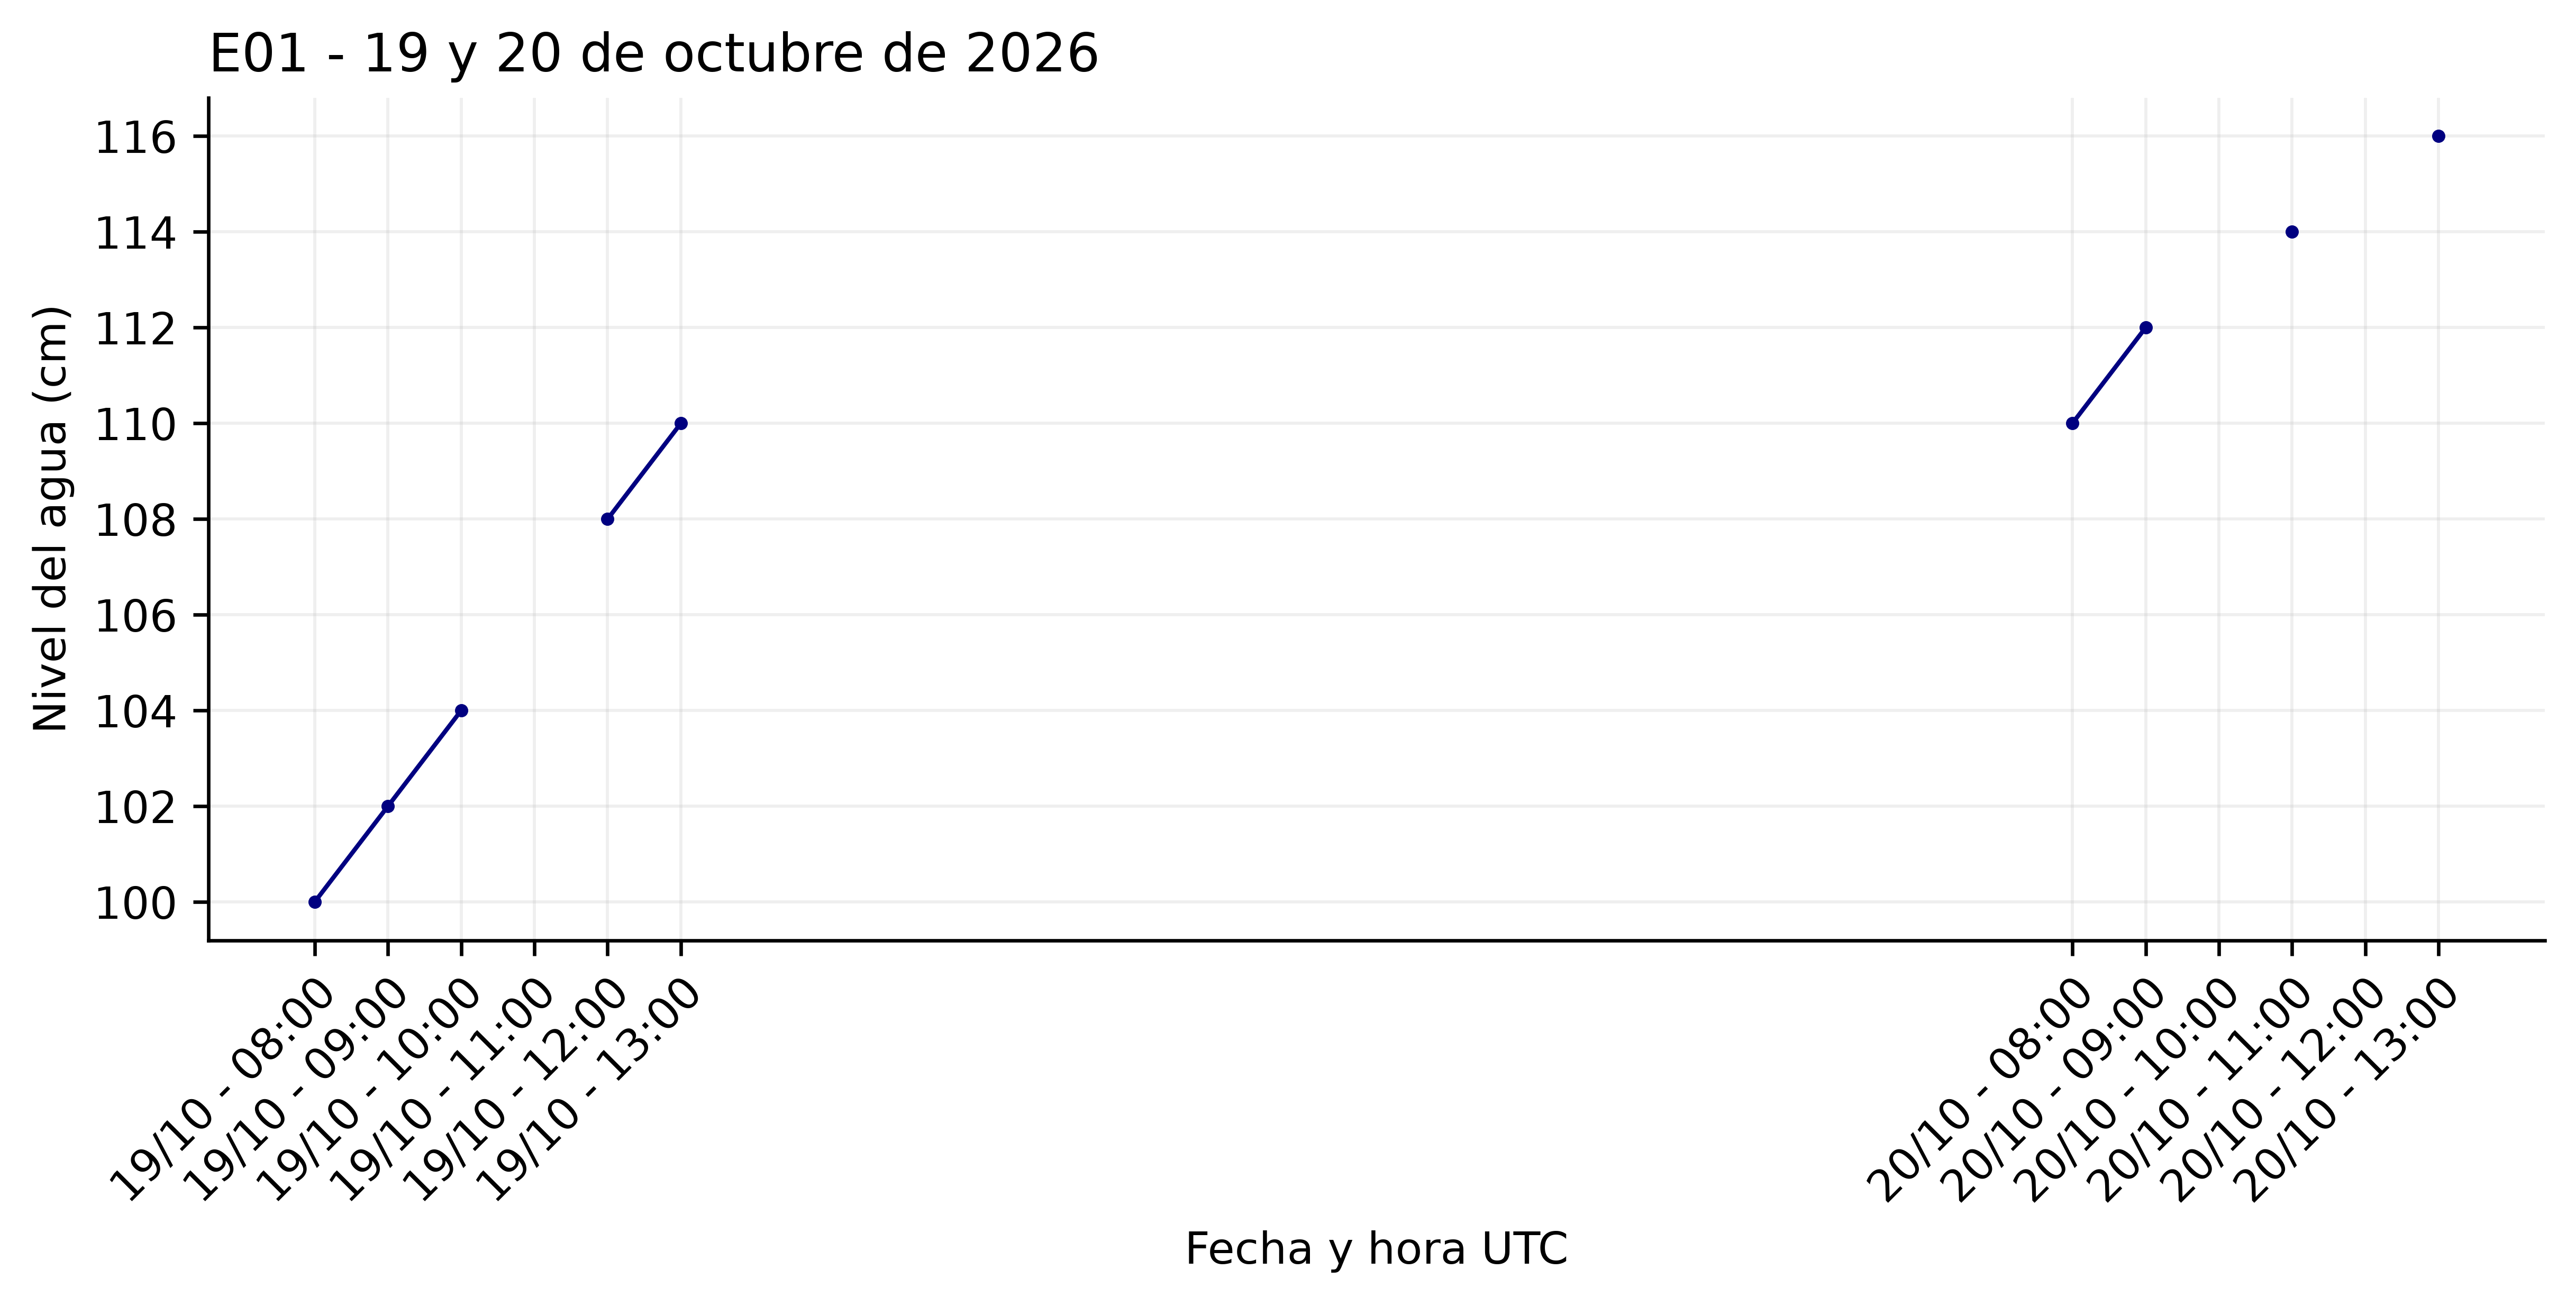

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

tiempo = pd.date_range("2026-10-19 08:00", "2026-10-20 13:00", freq="h", tz="UTC")
tiempo = tiempo[(tiempo.hour >= 8) & (tiempo.hour <= 13)]

nivel = pd.Series(
    [100, 102, 104, None, 108, 110, 110, 112, None, 114, None, 116],
    index=tiempo
)

fig, ax = plt.subplots(figsize=(8, 4), dpi=600, constrained_layout=True)

for _, dia in nivel.groupby(nivel.index.date):
    ax.plot(dia.index, dia, "o-", color="navy", linewidth=1, markersize=2)

ax.set_xticks(tiempo)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m - %H:%M", tz="UTC"))
ax.set(xlabel="Fecha y hora UTC", ylabel="Nivel del agua (cm)")
ax.set_title("E01 - 19 y 20 de octubre de 2026", loc="left")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

ax.grid(axis="both", alpha=0.2, linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)

plt.show()

## 5. Agregación temporal

Una agregación temporal resume observaciones en períodos definidos, como horas, días o meses. Para que el resultado sea interpretable, debe conservar la identidad de la serie, utilizar el campo temporal correspondiente y aplicar una operación adecuada a la variable.

En un resumen diario por estación, cada grupo reúne las lecturas de una misma estación observadas durante un día UTC:

In [19]:
%%sql
SELECT estacion_id,
       DATE(instante_observado_utc) AS dia_utc,
       COUNT(*) AS registros,
       COUNT(nivel_cm) AS valores_disponibles,
       MIN(nivel_cm) AS minimo_cm,
       MAX(nivel_cm) AS maximo_cm,
       ROUND(AVG(nivel_cm), 2) AS promedio_cm
FROM lectura
GROUP BY estacion_id, DATE(instante_observado_utc)
ORDER BY estacion_id, dia_utc;

,estacion_id,dia_utc,registros,valores_disponibles,minimo_cm,maximo_cm,promedio_cm
0,E01,2026-10-19,6,5,100.0,110.0,104.8
1,E01,2026-10-20,4,4,110.0,116.0,113.0
2,E02,2026-10-19,3,2,0.0,20.0,10.0



- `DATE` extrae la fecha del instante observado.
- `GROUP BY` forma los grupos estación–día y las funciones de agregación calculan sus resúmenes.

| Función           | Resultado                             | Tratamiento de valores `NULL`            |
|:------------------|:--------------------------------------|:-----------------------------------------|
| `COUNT(*)`        | Cantidad de registros.                | Cuenta la fila aunque su nivel sea nulo. |
| `COUNT(nivel_cm)` | Cantidad de niveles disponibles.      | Excluye los niveles nulos.               |
| `MIN(nivel_cm)`   | Menor nivel disponible.               | Omite nulos.                             |
| `MAX(nivel_cm)`   | Mayor nivel disponible.               | Omite nulos.                             |
| `AVG(nivel_cm)`   | Promedio de los niveles disponibles.  | Omite nulos.                             |

Si un grupo no contiene niveles disponibles, `MIN`, `MAX` y `AVG` devuelven `NULL`, `COUNT(nivel_cm)` devuelve cero [@oracle_mysql80_aggregates].

El promedio describe los valores disponibles bajo las condiciones de selección. No representa necesariamente el nivel medio durante todo el día. Si algunos períodos contienen más lecturas, tienen mayor peso en el promedio simple. Un promedio ponderado por duración exigiría definir cómo se representa el nivel entre mediciones.

La operación también debe corresponder al significado de la variable. Sumar niveles instantáneos no produce automáticamente una cantidad física interpretable. En cambio, sumar cantidades acumuladas en períodos consecutivos puede ser pertinente si no existen superposiciones y las unidades son compatibles.

## 6. Cobertura de registros

La **cobertura de registros** expresa cuántas observaciones programadas tienen un registro en la base de datos. La **disponibilidad de valores** indica cuántos de esos registros contienen valor distinto de `NULL`. Ambas medidas describen la **completitud de la serie**, pero examinan condiciones diferentes.

Para calcular la completitud de una serie se necesita conocer el calendario esperado y la cantidad de registros. Contar las filas de una tabla solo permite identificar los registros existentes, pero no los valores ausentes. Estos últimos se reconocen al comparar los instantes programados con los instantes almacenados.

Por ejemplo, en `bd_temporal` en cada horario esperado puede presentarse tres situaciones:

| Situación             | Registro         | Valor de `nivel_cm`                |
|:----------------------|:-----------------|:-----------------------------------|
| Observación con nivel | Existe una fila. | Distinto de `NULL`. |
| Observación sin nivel | Existe una fila. | `NULL`.                            |
| Registro ausente      | No existe fila.  | No hay un atributo que evaluar.    |

La cobertura se evalúa comparando los horarios programados con las lecturas existentes. Entre los registros se distingue los que contienen un valor para nivel y cuáles tienen `NULL`. La existencia de registro no garantiza la existencia de valores.

La restricción `UNIQUE (estacion_id, instante_observado_utc)`, en la tabla `lectura`, asegura que cada horario coincida, como máximo, con una lectura por estación.

Suponga que en el caso de estudio se programan seis observaciones por estación, desde las 08:00 hasta las 13:00 UTC del 19 de octubre. Como la frecuencia es regular, el calendario puede generarse a partir del instante inicial y un incremento de una hora.

MySQL 8 permite generar el calendario mediante una expresión de tabla común (CTE) recursiva, declarada con `WITH RECURSIVE`. Su forma recursiva permite producir nuevos elementos a partir de los anteriores [@oracle_mysql80_date_series].

La siguiente consulta genera los horarios y calcula los recuentos:

In [11]:
%%sql
WITH RECURSIVE horario_esperado AS (
    SELECT CAST('2026-10-19 08:00:00' AS DATETIME) AS instante_utc
    UNION ALL
    SELECT instante_utc + INTERVAL 1 HOUR
    FROM horario_esperado
    WHERE instante_utc < '2026-10-19 13:00:00'
)
SELECT
    e.estacion_id,
    COUNT(*) AS esperados,
    COUNT(l.lectura_id) AS registrados,
    COUNT(l.nivel_cm) AS con_nivel,
    COUNT(l.lectura_id) - COUNT(l.nivel_cm) AS sin_nivel,
    COUNT(*) - COUNT(l.lectura_id) AS ausentes
FROM estacion AS e
CROSS JOIN horario_esperado AS h
LEFT JOIN lectura AS l
    ON l.estacion_id = e.estacion_id
   AND l.instante_observado_utc = h.instante_utc
GROUP BY e.estacion_id
ORDER BY e.estacion_id;

,estacion_id,esperados,registrados,con_nivel,sin_nivel,ausentes
0,E01,6,6,5,1,0
1,E02,6,3,2,1,3


La primera parte de la CTE establece las `08:00` como instante inicial y define su tipo `DATETIME`. La segunda consulta la propia CTE y suma una hora al instante anterior. La condición de continuación permite generar las 13:00, pero impide producir las 14:00. Así se obtienen los seis horarios del calendario.

`CROSS JOIN` combina cada estación con esos horarios. `LEFT JOIN` busca la lectura correspondiente y conserva el horario aunque no encuentre ninguna. En resumen, la consulta parte de lo que debería existir y comprueba el registro actual.

En este resultado, los conteos tienen funciones específicas:

- `COUNT(*)` cuenta los horarios esperados conservados por la unión.
- `COUNT(l.lectura_id)` cuenta las lecturas encontradas.
- `COUNT(l.nivel_cm)` cuenta las lecturas con nivel no nulo.

La estación E01 tiene cobertura completa de registros, aunque uno carece de valor para el nivel. La estación E02 presenta un registro sin nivel y tres horarios sin registro.

El calendario esperado también permite conservar los días sin lecturas en un resumen. Esto es necesario porque `GROUP BY` solo genera grupos para las fechas presentes en los datos.

La siguiente consulta combina cada estación con dos fechas y resume sus observaciones:


In [12]:
%%sql
SELECT
    e.estacion_id,
    d.dia AS dia_utc,
    COUNT(l.lectura_id) AS registros,
    COUNT(l.nivel_cm) AS valores_disponibles,
    ROUND(AVG(l.nivel_cm), 2) AS promedio_cm
FROM estacion AS e
CROSS JOIN (
    SELECT CAST('2026-10-19' AS DATE) AS dia
    UNION ALL
    SELECT CAST('2026-10-20' AS DATE)
) AS d
LEFT JOIN lectura AS l
    ON l.estacion_id = e.estacion_id
   AND l.instante_observado_utc >= d.dia
   AND l.instante_observado_utc < d.dia + INTERVAL 1 DAY
GROUP BY e.estacion_id, d.dia
ORDER BY e.estacion_id, d.dia;

,estacion_id,dia_utc,registros,valores_disponibles,promedio_cm
0,E01,2026-10-19,6,5,104.8
1,E01,2026-10-20,4,4,113.0
2,E02,2026-10-19,3,2,10.0
3,E02,2026-10-20,0,0,NaN


La relación `d` contiene las fechas esperadas. `CROSS JOIN` genera las combinaciones estación–fecha y `LEFT JOIN` conserva aquellas que no encuentran lecturas. En este caso, la correspondencia abarca todo el día, desde las 00:00 UTC, incluidas, hasta las 00:00 del día siguiente, excluidas.

`COUNT(l.lectura_id)` cuenta los registros encontrados. Si no existen lecturas, devuelve cero. En cambio, `COUNT(*)` contaría la fila conservada por la unión externa y produciría un recuento de uno.

En E02, el día 20 no contiene registros, por lo tanto, contiene niveles que puedan promediarse. La lectura 6 pertenece al día 19 según su instante observado, aunque se haya incorporado el día 20.

## 7. Cambio de estado (vigencia)

Cuando cambia el estado de una estación, se cierra la vigencia anterior y se incorpora una nueva. Sobrescribir únicamente el estado atribuiría la nueva condición a todo el período anterior y alteraría la historia.

Si E01 pasa a INACTIVA el 20 de octubre a las 14:00, la transformación es:

| Situación               | Estado    | Desde UTC    | Hasta UTC            |
|:------------------------|:----------|:-------------|:---------------------|
| Antes del cambio        | OPERATIVA | 19/oct 12:00 | Sin término conocido |
| Después: tramo anterior | OPERATIVA | 19/oct 12:00 | 20/oct 14:00         |
| Después: nuevo tramo    | INACTIVA  | 20/oct 14:00 | Sin término conocido |

El término anterior coincide con el nuevo inicio. Bajo la convención `[desde, hasta)`, las 14:00 pertenecen únicamente a la nueva vigencia.

Las dos escrituras se realizan dentro de una transacción para confirmarlas conjuntamente, conforme a la propiedad de atomicidad [@silberschatz2020]:


In [ ]:
%%sql
START TRANSACTION;

UPDATE estado_estacion
SET hasta_utc = '2026-10-20 14:00:00'
WHERE estado_id = 3 AND hasta_utc IS NULL;

INSERT INTO estado_estacion(estado_id, estacion_id, estado, desde_utc, hasta_utc)
VALUES (5, 'E01', 'INACTIVA', '2026-10-20 14:00:00', NULL);

COMMIT;



El ejemplo supone el estado inicial del caso. La vigencia 3 está abierta y el identificador 5 está disponible. Antes de confirmar, debe comprobarse que se cerró la fila esperada y se insertó la nueva. Ante un error, se ejecuta `ROLLBACK` para deshacer los cambios de la transacción.

Cerrar sin insertar dejaría un período sin estado, insertar sin cerrar produciría vigencias superpuestas.